In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [6]:
data=pd.read_csv("/home/saurabh/AI_PROJECTS/Hospital_stay_prediction/HealthCareAnalytics.csv")

In [262]:
def outliers(value):
    q1 = data[value].quantile(0.25)
    q3 = data[value].quantile(0.75)
    IQR = q3 - q1
    upper_limit = q3 + (1.5 * IQR)
    lower_limit = q1 - (1.5 * IQR)
    return [upper_limit, lower_limit]

In [263]:
display(data)

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144,Nov-20
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699,31-40
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235,Nov-20
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,Nov-20,3761,Nov-20


In [264]:
data.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


In [265]:
data.tail()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144,Nov-20
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699,31-40
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235,Nov-20
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,Nov-20,3761,Nov-20
318437,318438,19,a,7,Y,5,gynecology,Q,C,2.0,21641,8.0,Emergency,Minor,2,Nov-20,4752,0-10


In [266]:
data.columns

Index(['case_id', 'Hospital_code', 'Hospital_type_code', 'City_Code_Hospital',
       'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital',
       'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade',
       'patientid', 'City_Code_Patient', 'Type_of_Admission',
       'Severity_of_Illness', 'Visitors_with_Patient', 'Age',
       'Admission_Deposit', 'Stay'],
      dtype='object')

In [267]:
data.dtypes

,0
case_id,int64
Hospital_code,int64
Hospital_type_code,object
City_Code_Hospital,int64
Hospital_region_code,object
Available_Extra_Rooms_in_Hospital,int64
Department,object
Ward_Type,object
Ward_Facility_Code,object
Bed_Grade,float64


In [268]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed_Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

In [269]:
data.describe()

,case_id,Hospital_code,City_Code_Hospital,Available_Extra_Rooms_in_Hospital,Bed_Grade,patientid,City_Code_Patient,Visitors_with_Patient,Admission_Deposit
count,318438.000000,318438.000000,318438.000000,318438.000000,318325.000000,318438.000000,313906.000000,318438.000000,318438.000000
mean,159219.500000,18.318841,4.771717,3.197627,2.625807,65747.579472,7.251859,3.284099,4880.749392
std,91925.276847,8.633755,3.102535,1.168171,0.873146,37979.936440,4.745266,1.764061,1086.776254
min,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1800.000000
25%,79610.250000,11.000000,2.000000,2.000000,2.000000,32847.000000,4.000000,2.000000,4186.000000
50%,159219.500000,19.000000,5.000000,3.000000,3.000000,65724.500000,8.000000,3.000000,4741.000000
75%,238828.750000,26.000000,7.000000,4.000000,3.000000,98470.000000,8.000000,4.000000,5409.000000
max,318438.000000,32.000000,13.000000,24.000000,4.000000,131624.000000,38.000000,32.000000,11008.000000


In [270]:
data.isnull().sum()

,0
case_id,0
Hospital_code,0
Hospital_type_code,0
City_Code_Hospital,0
Hospital_region_code,0
Available_Extra_Rooms_in_Hospital,0
Department,0
Ward_Type,0
Ward_Facility_Code,0
Bed_Grade,113


In [271]:
data["Bed_Grade"] = data["Bed_Grade"].fillna(data["Bed_Grade"].mode()[0])

In [272]:
data.isnull().sum()

,0
case_id,0
Hospital_code,0
Hospital_type_code,0
City_Code_Hospital,0
Hospital_region_code,0
Available_Extra_Rooms_in_Hospital,0
Department,0
Ward_Type,0
Ward_Facility_Code,0
Bed_Grade,0


In [273]:
data["City_Code_Patient"] = data["City_Code_Patient"].fillna(data["City_Code_Patient"].mode()[0])

In [274]:
data.isnull().sum()

,0
case_id,0
Hospital_code,0
Hospital_type_code,0
City_Code_Hospital,0
Hospital_region_code,0
Available_Extra_Rooms_in_Hospital,0
Department,0
Ward_Type,0
Ward_Facility_Code,0
Bed_Grade,0


In [275]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed_Grade                          318438 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3184

In [276]:
data["Stay"] = data["Stay"].replace({"Nov-20": "11-20"})

encoding = LabelEncoder()

categorical_to_encode = [
    "Hospital_type_code",
    "Hospital_region_code",
    "Ward_Type",
    "Ward_Facility_Code",
    "Type_of_Admission",
    "Severity_of_Illness",
    "Department",
    "Age",
    "Stay"
]

for col in categorical_to_encode:
    data[col] = data[col].fillna("Unknown").astype(str)
    data[col] = LabelEncoder().fit_transform(data[col])

In [277]:
print(data["Department"].unique())

[3 1 2 0 4]


In [278]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  int64  
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  int64  
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  int64  
 7   Ward_Type                          318438 non-null  int64  
 8   Ward_Facility_Code                 318438 non-null  int64  
 9   Bed_Grade                          318438 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3184

In [279]:
data.duplicated().sum()

np.int64(0)

## Exploratory Data Analysis

### Univariant Analysis

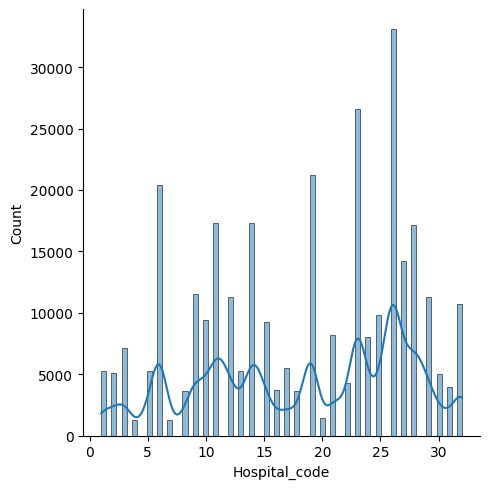

In [280]:
sns.displot(x=data.Hospital_code,kde=True)

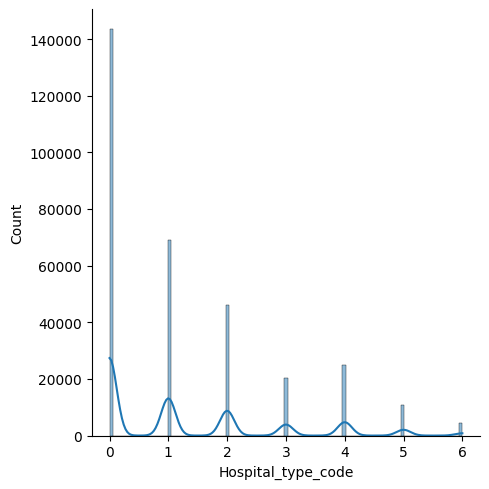

In [281]:
sns.displot(x=data.Hospital_type_code,kde=True)

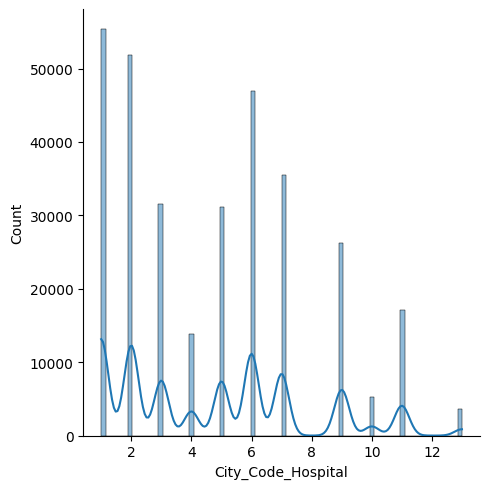

In [282]:
sns.displot(x=data.City_Code_Hospital,kde=True)

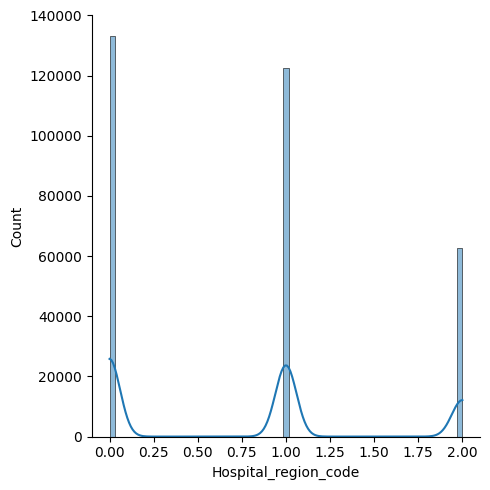

In [283]:
sns.displot(x=data.Hospital_region_code,kde=True)

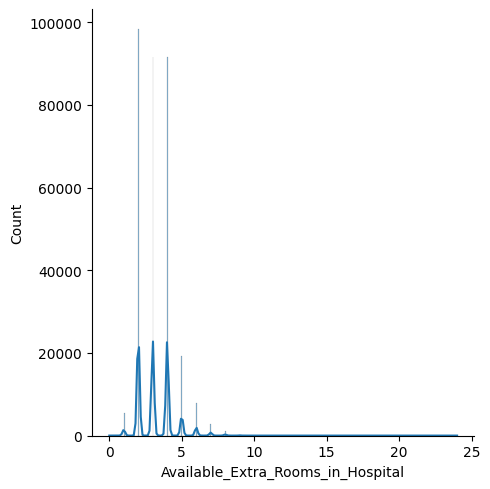

In [284]:
sns.displot(x=data.Available_Extra_Rooms_in_Hospital,kde=True)

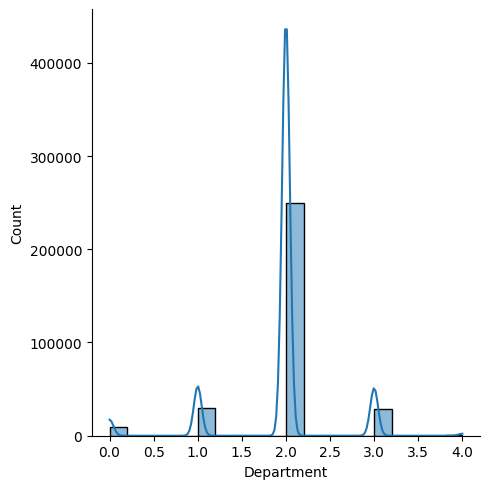

In [285]:
sns.displot(x=data.Department,kde=True)

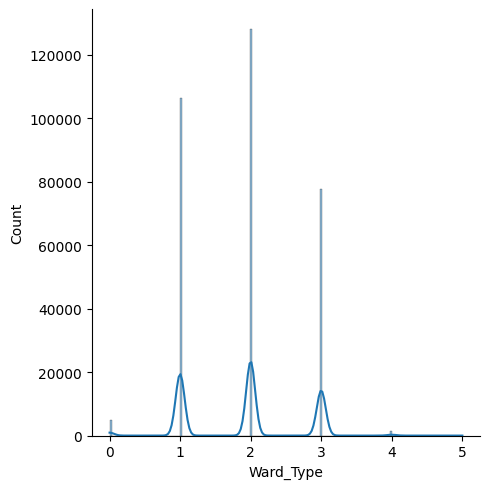

In [286]:

sns.displot(x=data.Ward_Type,kde=True)

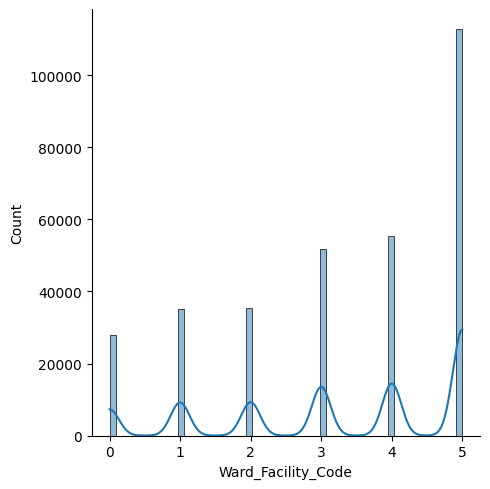

In [287]:
sns.displot(x=data.Ward_Facility_Code,kde=True)

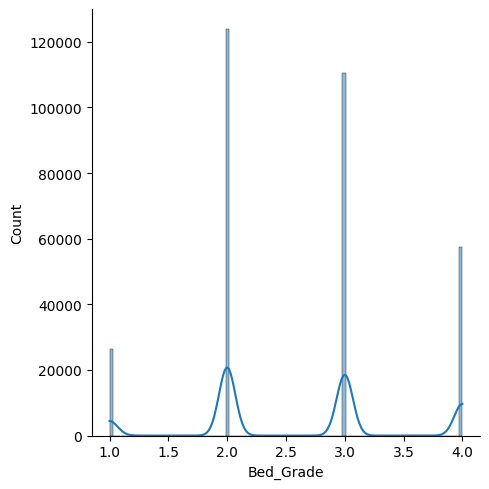

In [288]:
sns.displot(x=data.Bed_Grade,kde=True)

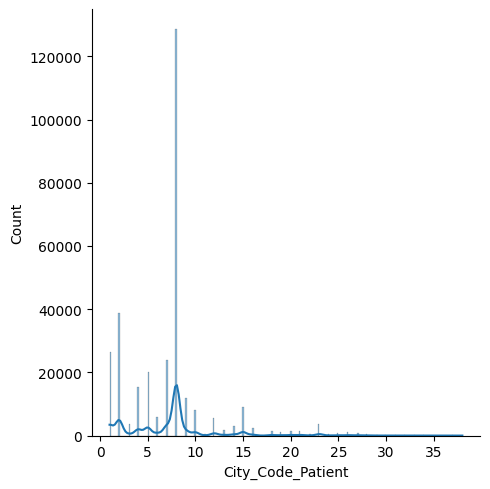

In [289]:
sns.displot(x=data.City_Code_Patient,kde=True)

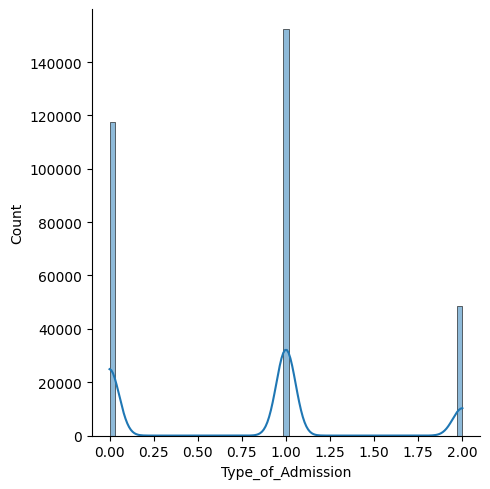

In [290]:
sns.displot(x=data.Type_of_Admission,kde=True)

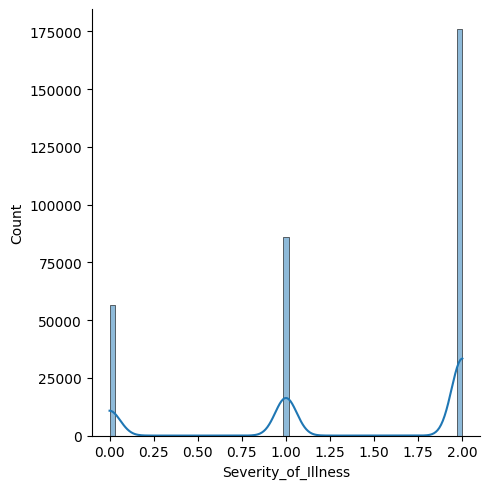

In [291]:
sns.displot(x=data.Severity_of_Illness,kde=True)

In [292]:
data.columns

Index(['case_id', 'Hospital_code', 'Hospital_type_code', 'City_Code_Hospital',
       'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital',
       'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade',
       'patientid', 'City_Code_Patient', 'Type_of_Admission',
       'Severity_of_Illness', 'Visitors_with_Patient', 'Age',
       'Admission_Deposit', 'Stay'],
      dtype='object')

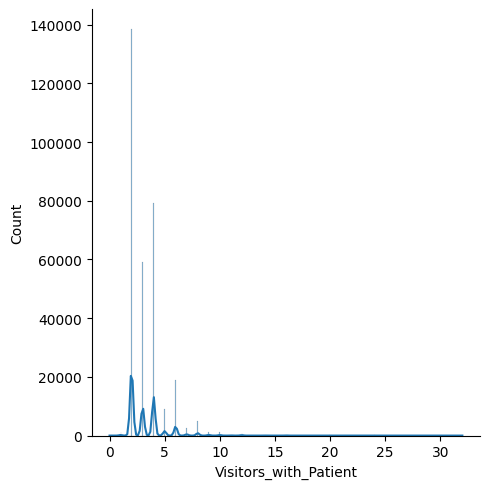

In [293]:
sns.displot(x=data.Visitors_with_Patient,kde=True)

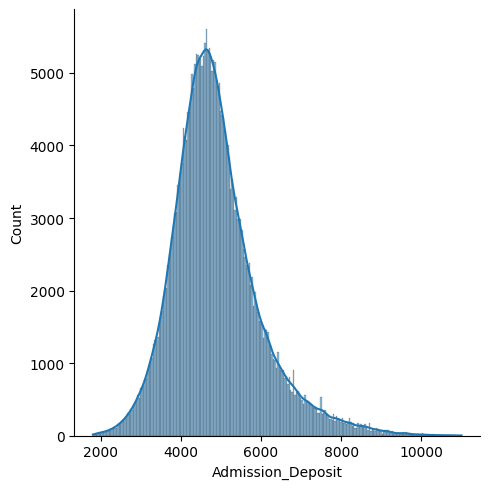

In [294]:
sns.displot(x=data.Admission_Deposit,kde=True)

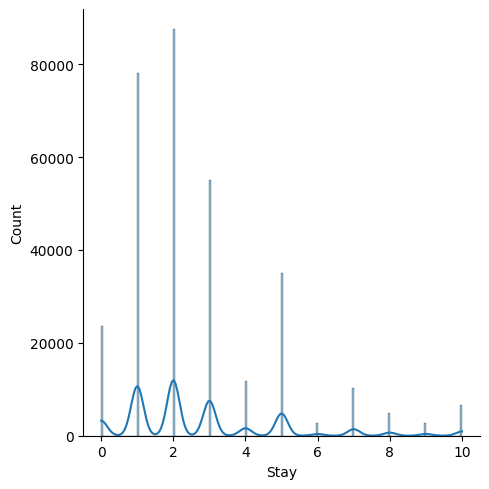

In [295]:
sns.displot(x=data.Stay,kde=True)

# Conclusion of univariant analysis
* Admision deposite have equal amount of distribution . normal skewed data.  
* and other features represents unequal amount of distribution .

## Bivariate analysis

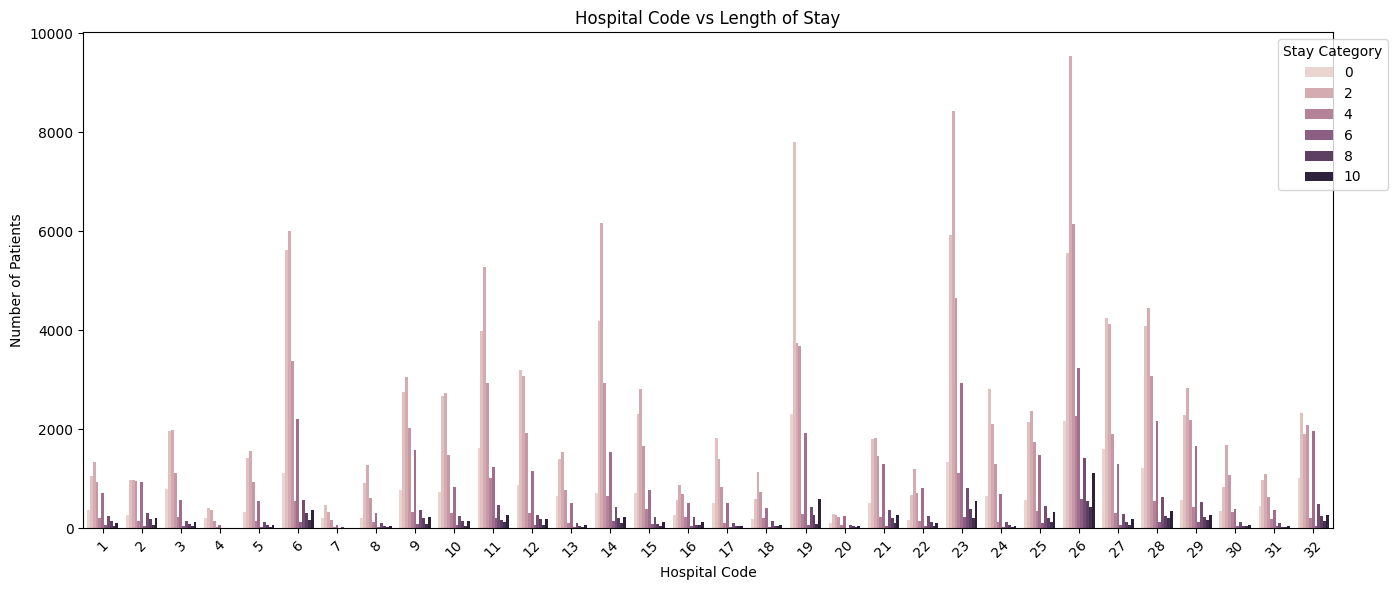

In [390]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Hospital_code',
    hue='Stay'
)

plt.title('Hospital Code vs Length of Stay')
plt.xlabel('Hospital Code')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Observation
* Hospital codes 19, 23, and 26 have particularly tall bars, indicating high patient counts in some stay categories. Hospital 26 appears to have the tallest bar, reaching approximately 9,500 patients.
* This suggests that the number of patient records varies substantially across hospitals.

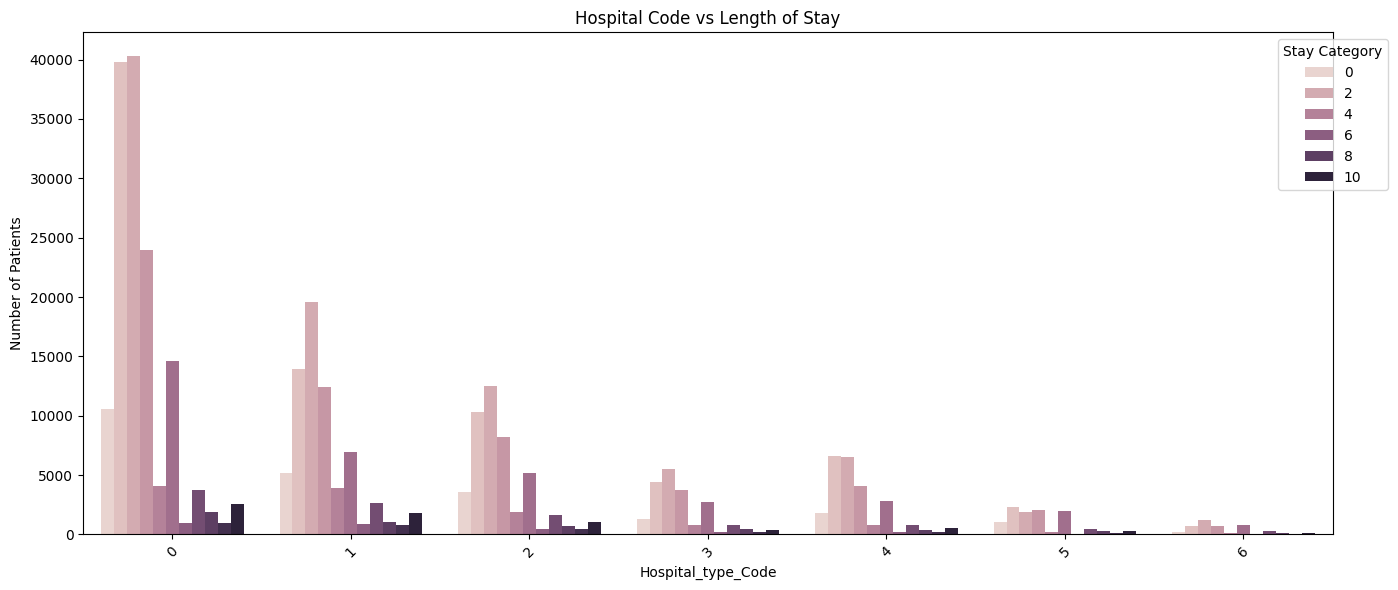

In [392]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Hospital_type_code',
    hue='Stay'
)

plt.title('Hospital type Code vs Length of Stay')
plt.xlabel('Hospital_type_Code')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Observations
* Hospital Code 0 have highest number of stay .
* Second Highest patient are in 1 hospital code.
* 0 hospital type code needs more beds and quality of infrastructure as compared to the other hospital type code .

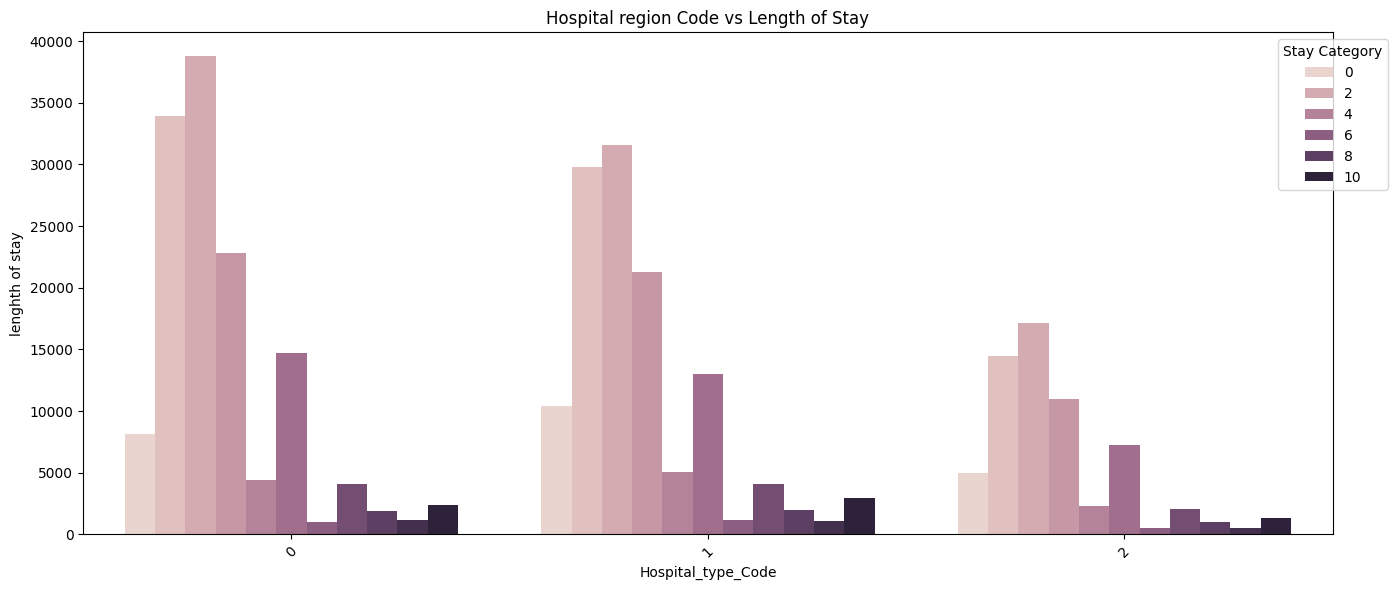

In [394]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Hospital_region_code',
    hue='Stay'
)

plt.title('Hospital region Code vs Length of Stay')
plt.xlabel('Hospital_type_Code')
plt.ylabel('lenghth of stay')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Conclusion
* Number 0 has highest number of patient stay
* Hospital management should investigate its admission volume and resource requirements.
* Group 1 may also require considerable resources. Comparing its bed occupancy, staffing, and patient mix with Group 0 could help identify differences in operational requirements.

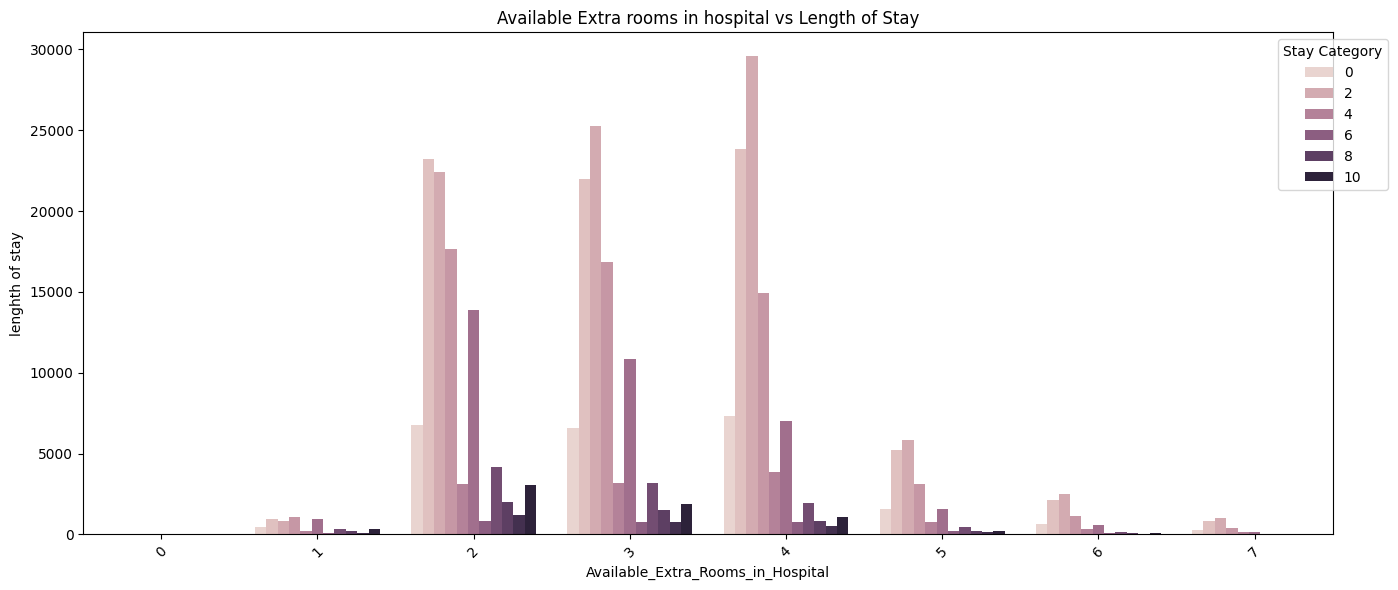

In [395]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Available_Extra_Rooms_in_Hospital',
    hue='Stay'
)

plt.title('Available Extra rooms in hospital vs Length of Stay')
plt.xlabel('Available_Extra_Rooms_in_Hospital')
plt.ylabel('lenghth of stay')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Conlcusion
* Hospitals with 2–4 extra rooms may represent a substantial share of the patients in this dataset. Hospital administrators should examine whether these facilities experience greater demand relative to their available capacity.
* Hospital managers should investigate which patient groups account for the largest share of admissions and whether staffing, beds, and other resources are appropriately allocated to meet their needs.

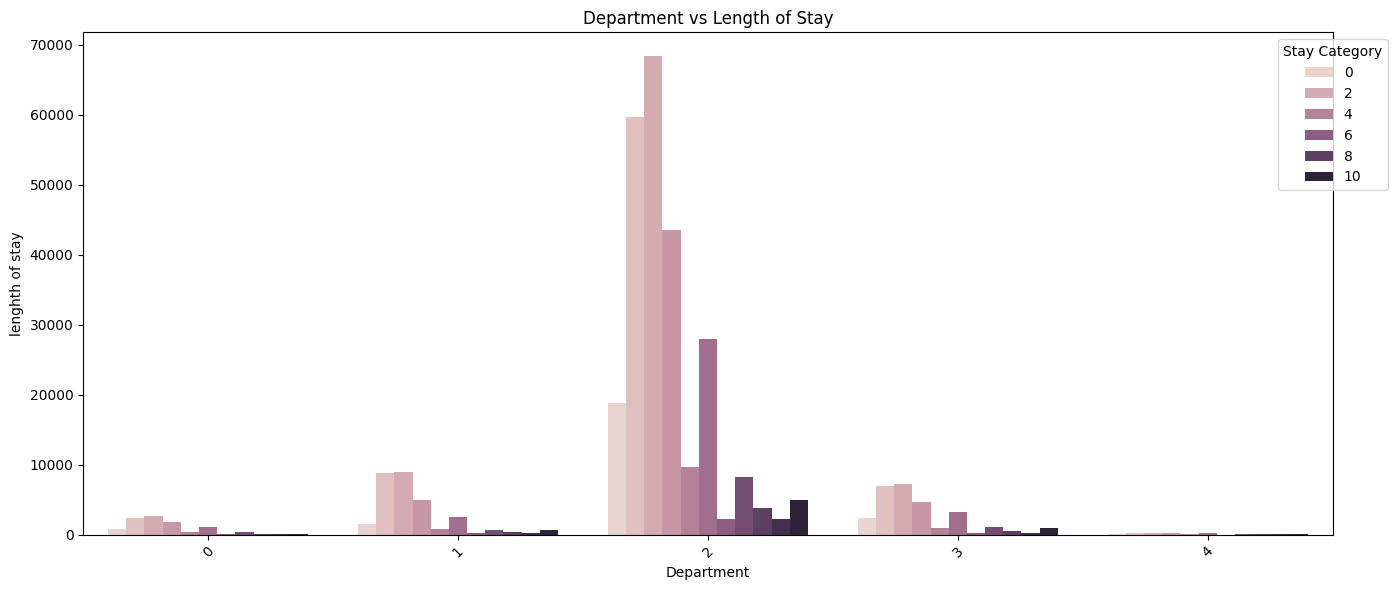

In [396]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Department',
    hue='Stay'
)

plt.title('Department vs Length of Stay')
plt.xlabel('Department')
plt.ylabel('lenghth of stay')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Conlcusion
* department 2 has highest number of patient stay .
* Its two tallest bars reach approximately 68,000 and 60,000 patients, while another category reaches around 43,000.
* Hospital management should examine Department 2's workload, staffing levels, bed occupancy, and resource requirements. If this department also has high occupancy rates, additional resources or improved patient-flow processes may be needed.

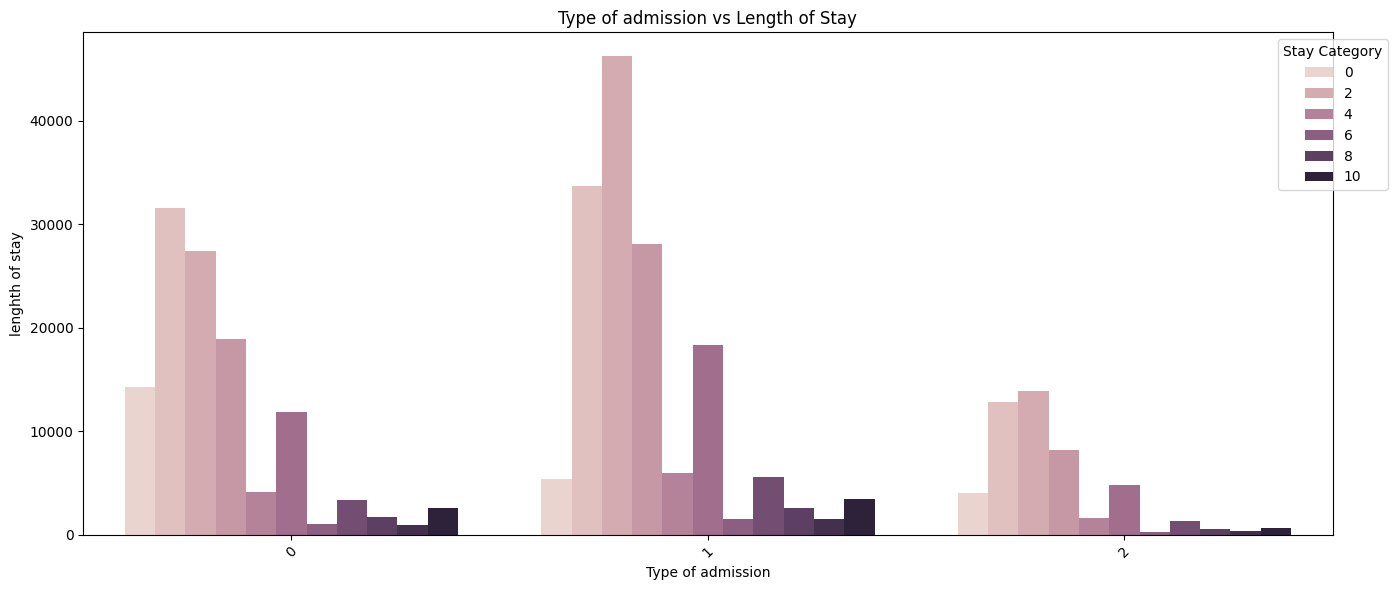

In [397]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Type_of_Admission',
    hue='Stay'
)

plt.title('Type of admission vs Length of Stay')
plt.xlabel('Type of admission')
plt.ylabel('lenghth of stay')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Conclussion
* type 1 have highest number of patient stay .
* This suggests that Admission Type 1 accounts for a substantial share of the patients in this dataset.
* Its largest bar is approximately 31,500 records.
* Several other stay categories also have considerable counts, including bars around 27,500 and 19,000.

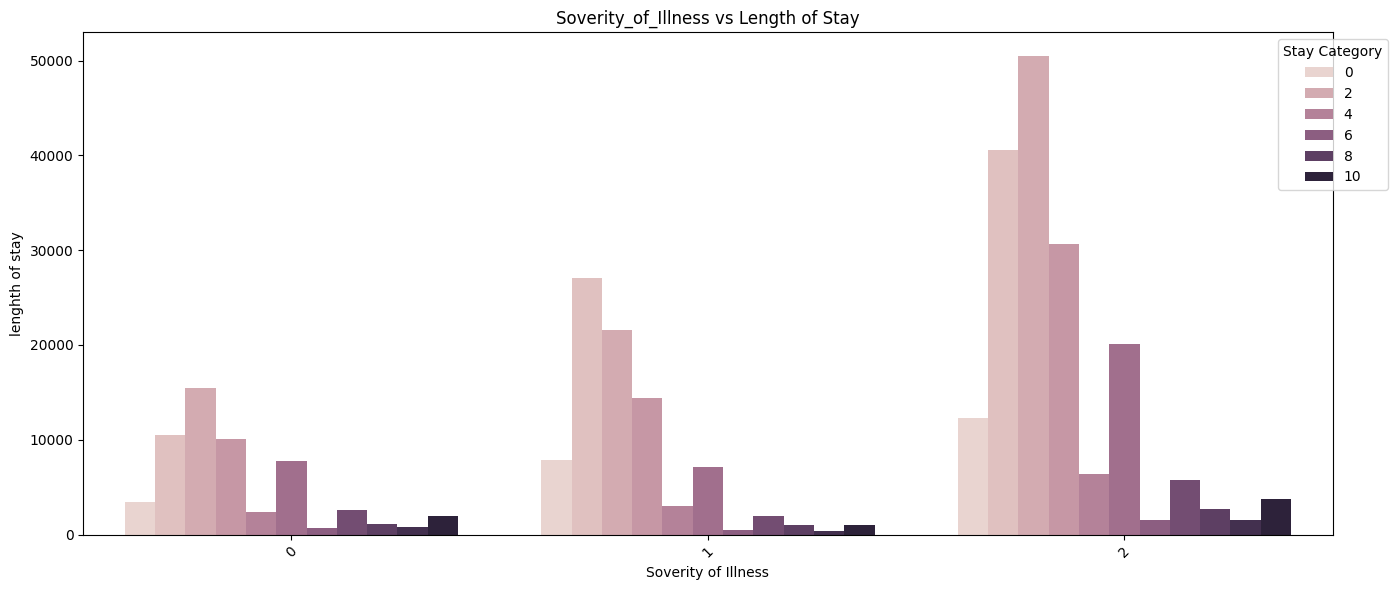

In [399]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Severity_of_Illness',
    hue='Stay'
)

plt.title('Soverity_of_Illness vs Length of Stay')
plt.xlabel('Soverity of Illness')
plt.ylabel('lenghth of stay')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Conclusion
* soverity of illness 2 have highest number of patient stay as compared to 0 and 1 .
* It also has relatively high counts in several other stay categories.
* Severity category 1 also represents a significant patient group and should be included in resource planning

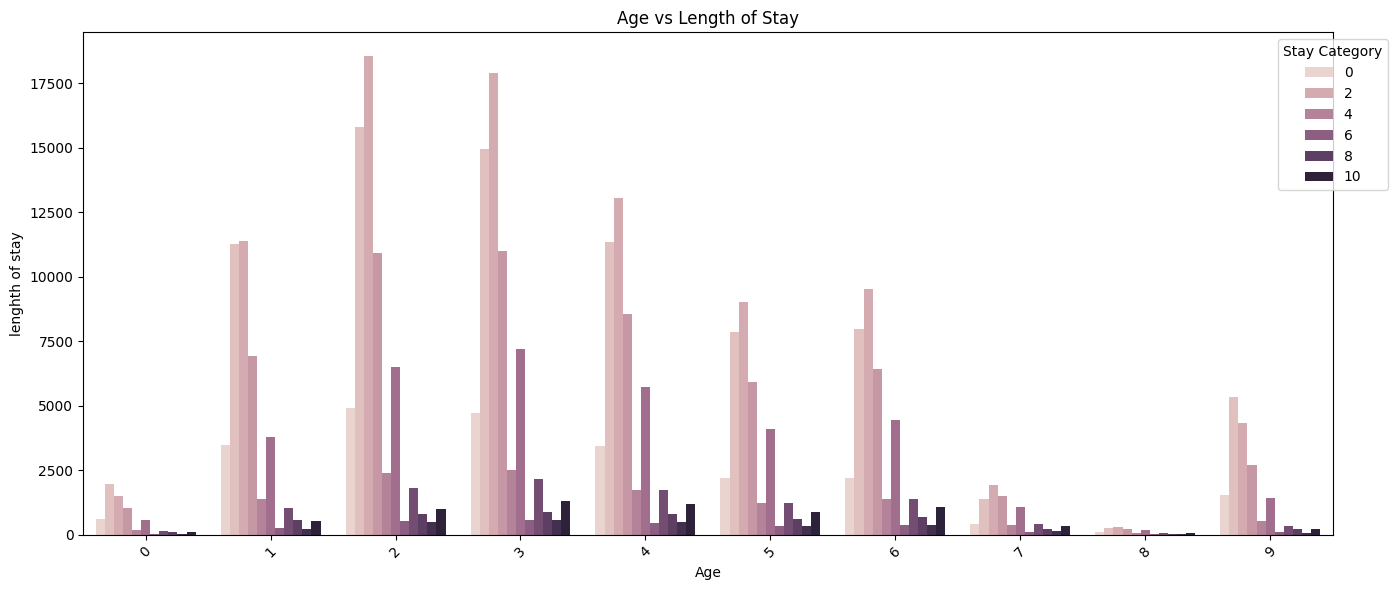

In [400]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x='Age',
    hue='Stay'
)

plt.title('Age vs Length of Stay')
plt.xlabel('Age')
plt.ylabel('lenghth of stay')
plt.xticks(rotation=45)
plt.legend(title='Stay Category', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Conclusion
* age group 2 have highest number of patient stay and the 3 have second highest number of patient.
* Categories 2 and 3 appear to account for a substantial proportion of the records shown.
* The highest bar for age category 4 is approximately 13,000 patients.
* Patient counts are lower than those in age categories 2 and 3.

In [305]:
data.columns

Index(['case_id', 'Hospital_code', 'Hospital_type_code', 'City_Code_Hospital',
       'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital',
       'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade',
       'patientid', 'City_Code_Patient', 'Type_of_Admission',
       'Severity_of_Illness', 'Visitors_with_Patient', 'Age',
       'Admission_Deposit', 'Stay'],
      dtype='object')

<Axes: xlabel='Hospital_code'>

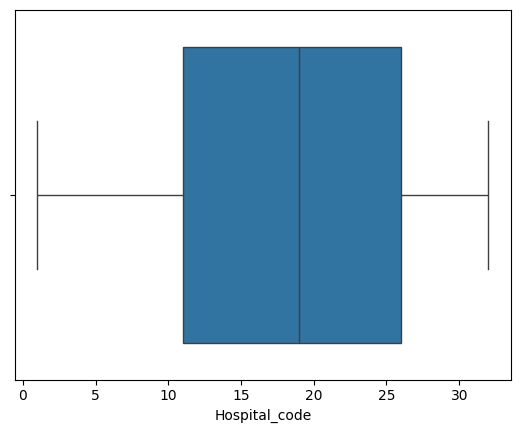

In [306]:
sns.boxplot(x=data.Hospital_code)

<Axes: xlabel='Available_Extra_Rooms_in_Hospital'>

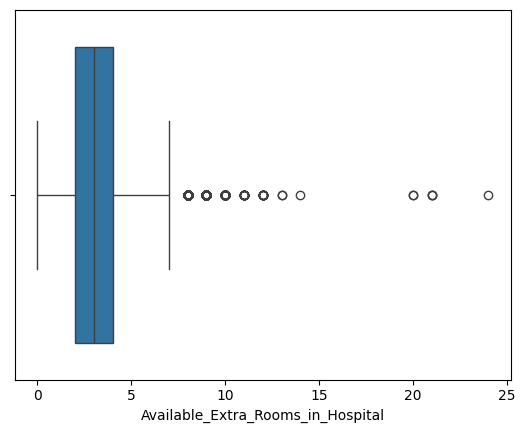

In [307]:
sns.boxplot(x=data.Available_Extra_Rooms_in_Hospital)

In [308]:
q1=data['Available_Extra_Rooms_in_Hospital'].quantile(0.25)
q3=data['Available_Extra_Rooms_in_Hospital'].quantile(0.75)

In [309]:
print(q1)
print(q3)

2.0
4.0


In [310]:
IQR=q3-q1

In [311]:
print(IQR)

2.0


In [312]:
lower_limit=q1-(1.5*IQR)

In [313]:
print(lower_limit)

-1.0


In [314]:
upper_limit=q3+(1.5*IQR)


In [315]:
print(upper_limit)

7.0


In [316]:
data.loc[data['Available_Extra_Rooms_in_Hospital']>upper_limit]

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
110,111,9,3,5,2,8,2,1,5,2.0,110115,8.0,0,2,4,6,3035,2
317,318,26,1,2,1,9,2,0,3,1.0,115145,5.0,0,0,4,4,3623,4
413,414,26,1,2,1,8,3,0,3,3.0,3372,2.0,0,0,6,1,4584,2
593,594,6,0,6,0,8,2,1,5,2.0,83674,8.0,1,0,4,3,3716,2
1006,1007,26,1,2,1,10,3,0,3,2.0,80113,4.0,1,2,4,3,4216,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317206,317207,23,0,6,0,8,2,1,5,4.0,76891,10.0,2,1,2,3,4299,2
317550,317551,14,0,1,0,8,2,0,4,3.0,16023,8.0,2,2,4,3,4513,5
317754,317755,14,0,1,0,8,2,0,4,1.0,125874,10.0,2,2,2,2,3022,1
318045,318046,14,0,1,0,9,2,0,4,2.0,93901,1.0,2,2,5,5,3937,3


In [317]:
data.loc[data['Available_Extra_Rooms_in_Hospital']<lower_limit]

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay


In [318]:
data.loc[
    data["Available_Extra_Rooms_in_Hospital"] > upper_limit,
    "Available_Extra_Rooms_in_Hospital"
] = data["Available_Extra_Rooms_in_Hospital"].median()

<Axes: xlabel='Available_Extra_Rooms_in_Hospital'>

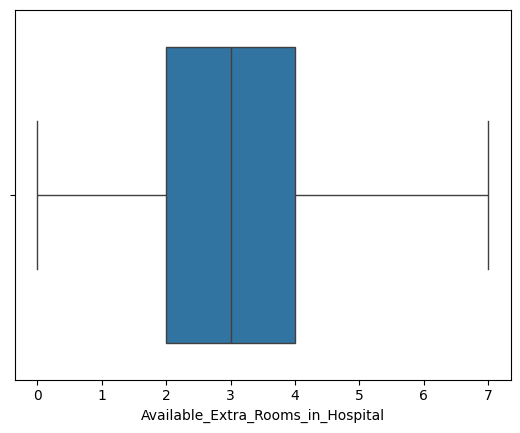

In [319]:
sns.boxplot(x=data.Available_Extra_Rooms_in_Hospital)

<Axes: xlabel='Department'>

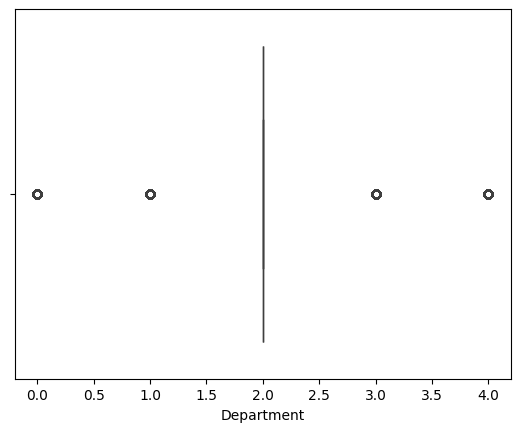

In [320]:
sns.boxplot(x=data.Department)

In [321]:
display(data["Department"].value_counts().sort_index())

,count
Department,
0,9586
1,29649
2,249486
3,28516
4,1201


In [322]:
pass

In [323]:
pass

In [324]:
pass

In [325]:
pass

In [326]:
display(data["Department"].value_counts().sort_index())

,count
Department,
0,9586
1,29649
2,249486
3,28516
4,1201


In [327]:
pass

In [328]:
display(data["Department"].value_counts().sort_index())

,count
Department,
0,9586
1,29649
2,249486
3,28516
4,1201


<Axes: xlabel='Department'>

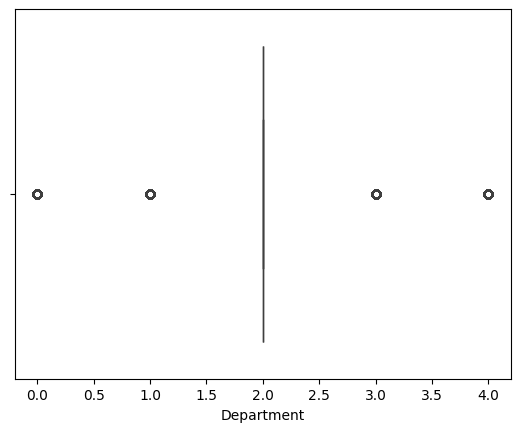

In [330]:
sns.boxplot(x=data.Department)

<Axes: xlabel='Ward_Type'>

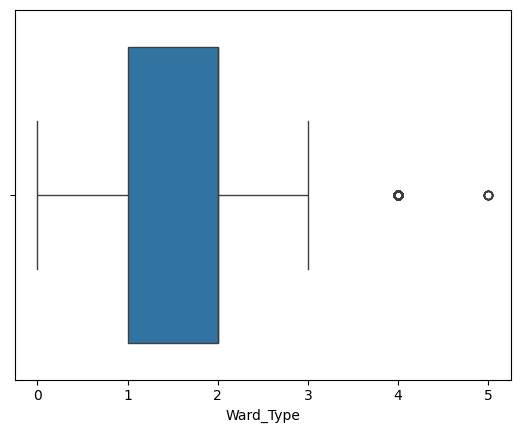

In [331]:
sns.boxplot(x=data.Ward_Type)

In [332]:
display(data["Ward_Type"].value_counts().sort_index())

,count
Ward_Type,
0,5046
1,106165
2,127947
3,77794
4,1477
5,9


In [333]:
pass

In [334]:
display(data["Ward_Type"].value_counts().sort_index())

,count
Ward_Type,
0,5046
1,106165
2,127947
3,77794
4,1477
5,9


In [336]:
display(data["Ward_Type"].value_counts().sort_index())

,count
Ward_Type,
0,5046
1,106165
2,127947
3,77794
4,1477
5,9


<Axes: xlabel='Ward_Type'>

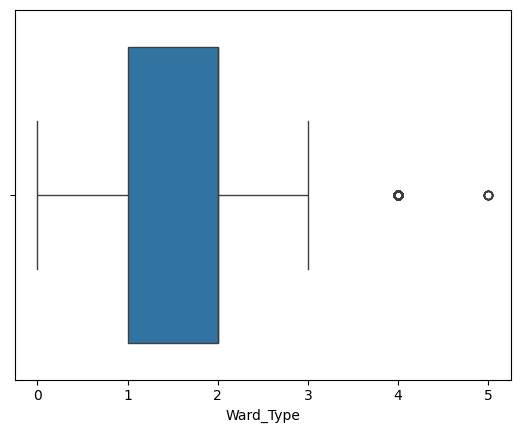

In [337]:
sns.boxplot(x=data.Ward_Type)

<Axes: ylabel='Severity_of_Illness'>

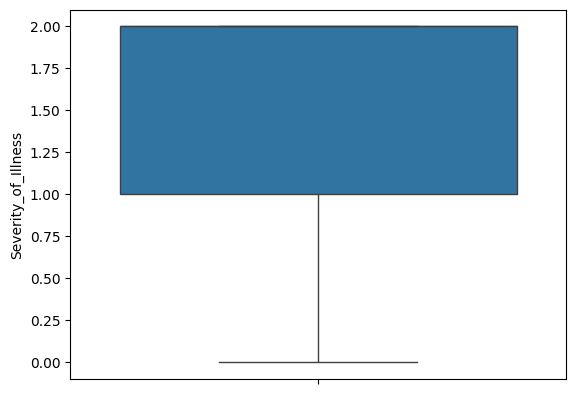

In [338]:
sns.boxplot(data.Severity_of_Illness)

<Axes: xlabel='Age'>

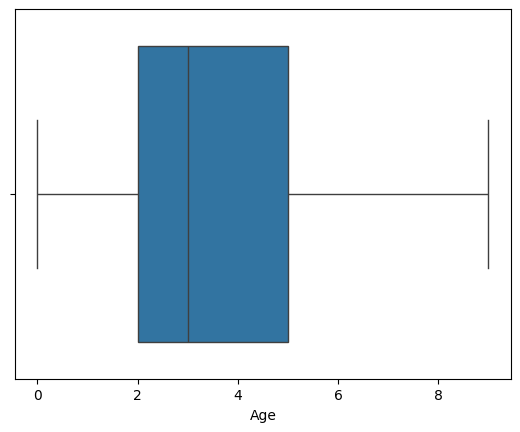

In [339]:
sns.boxplot(x=data.Age)

In [340]:
display(data["Age"].value_counts().sort_index())

,count
Age,
0,6254
1,40843
2,63639
3,63749
4,48514
5,33687
6,35792
7,7890
8,1302


<Axes: xlabel='Age'>

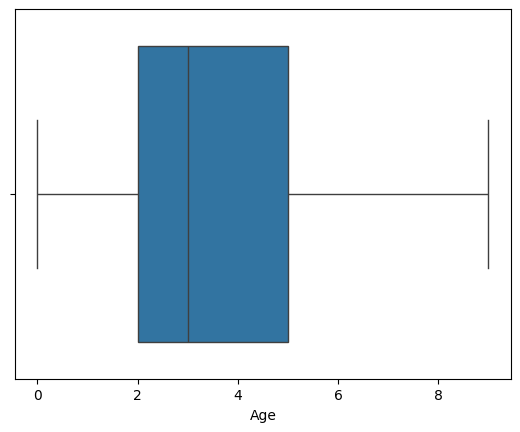

In [343]:
sns.boxplot(x=data.Age)

<Axes: xlabel='Stay'>

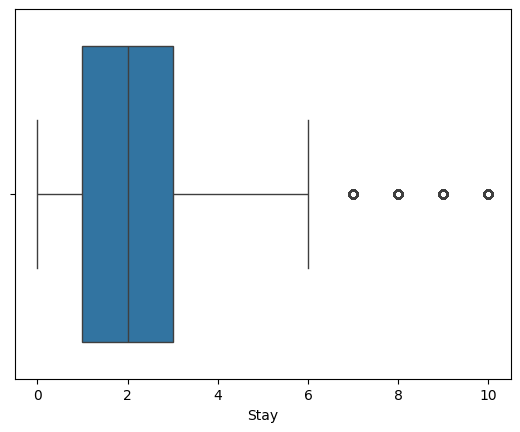

In [344]:
sns.boxplot(x=data.Stay)

In [345]:
display(data["Stay"].value_counts().sort_index())

,count
Stay,
0,23604
1,78139
2,87491
3,55159
4,11743
5,35018
6,2744
7,10254
8,4838


In [346]:
pass

<Axes: xlabel='Stay'>

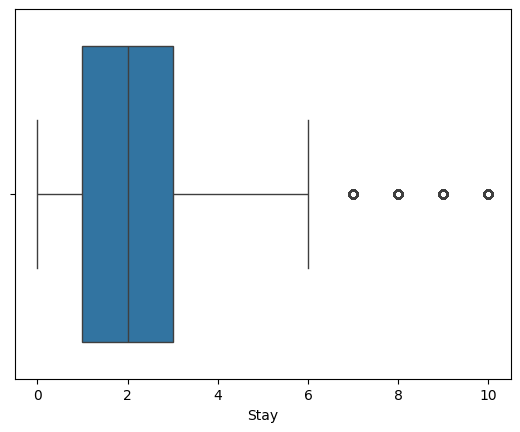

In [347]:

sns.boxplot(x=data.Stay)

<Axes: >

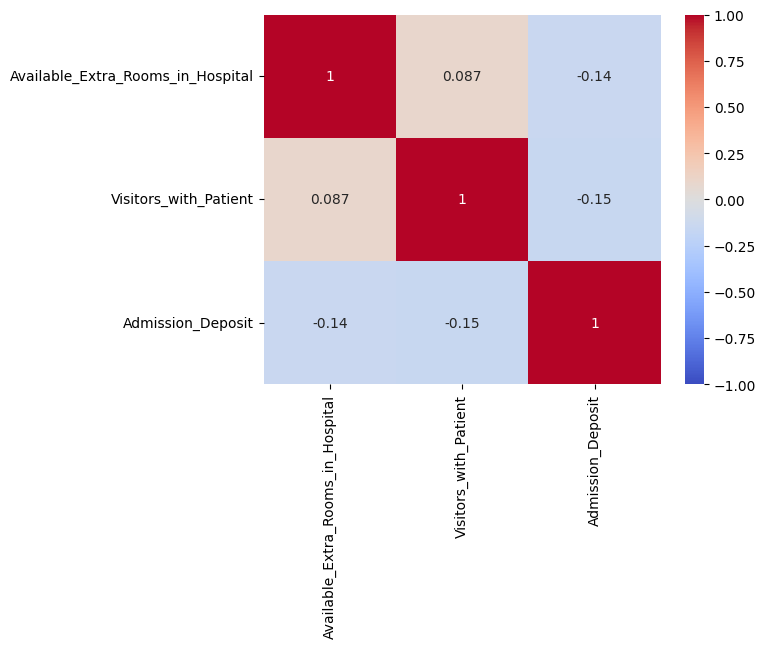

In [348]:
numeric_for_corr = [
    "Available_Extra_Rooms_in_Hospital",
    "Visitors_with_Patient",
    "Admission_Deposit"
]
sns.heatmap(data[numeric_for_corr].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)

In [349]:
data = data.drop(["case_id", "patientid"], axis=1)
x = data.drop("Stay", axis=1)
y = data["Stay"]

In [350]:
x

,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit
0,8,2,3,2,3,3,2,5,2.0,7.0,0,0,2,4,4911
1,2,2,5,2,2,3,3,5,2.0,7.0,1,0,2,4,5954
2,10,4,1,0,2,1,3,4,2.0,7.0,1,0,2,4,4745
3,26,1,2,1,2,3,2,3,2.0,7.0,1,0,2,4,7272
4,26,1,2,1,2,3,3,3,2.0,7.0,1,0,2,4,5558
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,6,0,6,0,3,3,1,5,4.0,23.0,0,2,3,3,4144
318434,24,0,1,0,2,1,1,4,4.0,8.0,2,2,4,7,6699
318435,7,0,4,0,3,2,2,5,4.0,10.0,0,1,3,6,4235
318436,11,1,2,1,3,1,1,3,3.0,8.0,1,1,5,9,3761


In [351]:
y

,Stay
0,0
1,4
2,3
3,4
4,4
...,...
318433,1
318434,3
318435,1
318436,1


## Model Creation of logistic regression

In [352]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=28,
)

In [353]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000, random_state=28)
clf.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=28)

In [354]:
y_pred=clf.predict(x_test)

In [355]:
y_pred

array([3, 1, 2, ..., 2, 1, 1])

In [356]:
y_pred_prob=clf.predict_proba(x_test)

In [357]:
y_pred_prob

array([[0.07116633, 0.18215055, 0.16977769, ..., 0.01424866, 0.00715966,
        0.01308237],
       [0.08777694, 0.31144925, 0.24756818, ..., 0.00876067, 0.00701272,
        0.00524194],
       [0.06390804, 0.25309774, 0.45846253, ..., 0.00739903, 0.00543641,
        0.00458531],
       ...,
       [0.06661513, 0.33417262, 0.43309463, ..., 0.00402644, 0.00294654,
        0.00143945],
       [0.09709698, 0.3805656 , 0.31395727, ..., 0.00923294, 0.00546387,
        0.00537896],
       [0.08175895, 0.48463833, 0.19149244, ..., 0.0056176 , 0.00410787,
        0.00379565]])

In [358]:
data.Stay.value_counts()

,count
Stay,
2,87491
1,78139
3,55159
5,35018
0,23604
4,11743
7,10254
10,6683
8,4838


In [359]:
from sklearn.metrics import confusion_matrix,accuracy_score,recall_score,precision_score,classification_report,f1_score

In [360]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[    0  1863  2513   391     0    17     0     0     0     0     1]
 [    0  5706  8199  1435     0   409     0     0     0     0     6]
 [    0  4782 11182  1138     0   294     0     0     0     0     9]
 [    0  2300  4308  3090     0  1295     0     0     0     0    19]
 [    0   553  1278   351     0   160     0     0     0     0    13]
 [    0   758  1270  2840     0  2070     0     0     0     0    21]
 [    0    95   223   105     0    97     0     0     0     0     5]
 [    0   197   291   885     0   630     0     0     0     0    40]
 [    0    45    55   171     0   660     0     0     0     0    18]
 [    0    54    71   251     0   174     0     0     0     0    23]
 [    0    86    78   205     0   865     0     0     0     0    93]]


In [361]:
recall=recall_score(y_test,y_pred,average='weighted')
recall


0.34764790855420175

In [362]:
precision=precision_score(y_test,y_pred,average='weighted')
precision

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


0.28047339376174374

In [363]:
f1score=f1_score(y_test,y_pred, average='weighted')
f1score

0.3025792386701935

In [364]:
cr = classification_report(y_test, y_pred, zero_division=0)
print(cr)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      4785
           1       0.35      0.36      0.35     15755
           2       0.38      0.64      0.48     17405
           3       0.28      0.28      0.28     11012
           4       0.00      0.00      0.00      2355
           5       0.31      0.30      0.30      6959
           6       0.00      0.00      0.00       525
           7       0.00      0.00      0.00      2043
           8       0.00      0.00      0.00       949
           9       0.00      0.00      0.00       573
          10       0.38      0.07      0.12      1327

    accuracy                           0.35     63688
   macro avg       0.15      0.15      0.14     63688
weighted avg       0.28      0.35      0.30     63688



In [365]:
y_test.value_counts()

,count
Stay,
2,17405
1,15755
3,11012
5,6959
0,4785
4,2355
7,2043
10,1327
8,949


## Model building of Random Forest


In [366]:
pass

In [367]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=28,
    n_jobs=-1,
    min_samples_leaf=2
)

In [368]:
model.fit(x_train,y_train)

RandomForestClassifier(min_samples_leaf=2, n_jobs=-1, random_state=28)

In [369]:
model.score(x_test,y_test)

0.409763220700917

In [370]:
y_pred = model.predict(x_test)

In [371]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision Score: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")

Accuracy Score: 0.4098
Precision Score: 0.3933
Confusion Matrix:
[[  782  2224  1658    95     2    23     0     0     0     0     1]
 [  525  7517  6222   933    14   527     0    12     4     0     1]
 [  353  5204 10668   794    33   309     0     3    18     0    23]
 [  206  2046  4023  2811    20  1812     1    56     8     2    27]
 [   71   511  1299   235    12   190     0     9     8     0    20]
 [   91   546   956  1650     6  3458     1    78    78     0    95]
 [   14    74   237    71     0   100     1     1     8     0    19]
 [   30   140   207   413     1  1013     0    96    10     2   131]
 [   12    32    48   113     1   481     1    10   157     0    94]
 [    4    37    56    98     2   259     1    23     3     9    81]
 [   12    61    68    90     0   398     1    25    84     2   586]]


In [372]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.37      0.16      0.23      4785
           1       0.41      0.48      0.44     15755
           2       0.42      0.61      0.50     17405
           3       0.38      0.26      0.31     11012
           4       0.13      0.01      0.01      2355
           5       0.40      0.50      0.45      6959
           6       0.17      0.00      0.00       525
           7       0.31      0.05      0.08      2043
           8       0.42      0.17      0.24       949
           9       0.60      0.02      0.03       573
          10       0.54      0.44      0.49      1327

    accuracy                           0.41     63688
   macro avg       0.38      0.24      0.25     63688
weighted avg       0.39      0.41      0.38     63688



## Decision Tree Model

In [373]:
pass

In [374]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=28
)

In [375]:
model.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=10, min_samples_split=20,
                       random_state=28)

In [376]:
model.score(x_test,y_test)

0.37022673031026254

In [377]:
y_predict=model.predict(x_test)

In [378]:
from sklearn.metrics import confusion_matrix ,accuracy_score,precision_score,recall_score,f1_score,classification_report
cm=confusion_matrix(y_test,y_predict)
cm

array([[ 947, 2010, 1536,  243,   19,   28,    0,    1,    0,    0,    1],
       [1089, 6805, 6021, 1273,   43,  467,    0,   35,    7,    2,   13],
       [ 808, 5522, 9316, 1344,   73,  254,    0,   18,   50,    1,   19],
       [ 387, 2321, 3508, 2903,   54, 1602,    0,  143,   42,    7,   45],
       [ 129,  549, 1131,  312,   32,  156,    0,   13,   10,    1,   22],
       [ 135,  742,  861, 1845,   20, 2744,    0,  277,  194,    8,  133],
       [  25,   95,  202,   82,    8,   67,    0,   17,   14,    0,   15],
       [  47,  192,  185,  481,    5,  822,    0,  155,   28,    8,  120],
       [  16,   61,   53,  128,    3,  358,    0,   37,  198,    2,   93],
       [  11,   46,   60,  133,    4,  186,    0,   53,    7,   21,   52],
       [  19,   62,   68,  143,    8,  287,    2,  109,  140,   31,  458]])

In [379]:
print("accuracy score = ",accuracy_score(y_test,y_predict))
print("Precision Score = ",precision_score(y_test,y_predict,average='weighted'))
print("recall score = ",recall_score(y_test,y_predict,average='weighted'))
print("f1_score = ", f1_score(y_test,y_predict,average='weighted'))

accuracy score =  0.37022673031026254
Precision Score =  0.34825621780327337
recall score =  0.37022673031026254
f1_score =  0.3520194625789562


In [380]:
print(classification_report(y_test, y_predict, zero_division=0))

              precision    recall  f1-score   support

           0       0.26      0.20      0.23      4785
           1       0.37      0.43      0.40     15755
           2       0.41      0.54      0.46     17405
           3       0.33      0.26      0.29     11012
           4       0.12      0.01      0.02      2355
           5       0.39      0.39      0.39      6959
           6       0.00      0.00      0.00       525
           7       0.18      0.08      0.11      2043
           8       0.29      0.21      0.24       949
           9       0.26      0.04      0.06       573
          10       0.47      0.35      0.40      1327

    accuracy                           0.37     63688
   macro avg       0.28      0.23      0.24     63688
weighted avg       0.35      0.37      0.35     63688



## Model Comparison Report

In this section, we compare Logistic Regression, Random Forest,
and Decision Tree using the same test dataset.

The evaluation metrics include accuracy, precision, recall,
weighted F1-score, and macro F1-score.

Macro F1-score is particularly important because the target
variable contains multiple stay-duration categories with
different numbers of observations.

In [385]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.3476,
        0.3702,
        0.4098
    ],
    "Weighted Precision": [
        0.2805,
        0.3483,
        0.3933
    ],
    "Weighted Recall": [
        0.3476,
        0.3702,
        0.4098
    ],
    "Weighted F1-Score": [
        0.3026,
        0.3520,
        0.3800
    ],
    "Macro F1-Score": [
        0.14,
        0.24,
        0.25
    ]
})

model_comparison = model_comparison.sort_values(
    by="Macro F1-Score",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score,Macro F1-Score
0,Random Forest,0.4098,0.3933,0.4098,0.3800,0.25
1,Decision Tree,0.3702,0.3483,0.3702,0.3520,0.24
2,Logistic Regression,0.3476,0.2805,0.3476,0.3026,0.14


In [386]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=28
)

decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=28
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=28,
    n_jobs=-1
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(x_train, y_train)

print("All three models have been trained.")

Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Decision Tree...
Training Random Forest...
All three models have been trained.


In [384]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

results = []

for name, model in models.items():
    y_pred_model = model.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred_model)

    precision = precision_score(
        y_test,
        y_pred_model,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_model,
        average="weighted",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred_model,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred_model,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred_model
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-Score": weighted_f1,
        "Macro F1-Score": macro_f1,
        "Balanced Accuracy": balanced_acc
    })
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Macro F1-Score",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score,Macro F1-Score,Balanced Accuracy
0,Random Forest,0.4098,0.3933,0.4098,0.3808,0.2516,0.2439
1,Decision Tree,0.3702,0.3483,0.3702,0.3520,0.2370,0.2275
2,Logistic Regression,0.3590,0.2885,0.3590,0.3130,0.1579,0.1682


## Conclusion 
* according to my conclusion Random Forest model is the best fit model for hosp